**BEATS PER MINUTE**

>Proyecto

>Predecir los beats por minuto de un determinado grupo de canciones tomando como referencia el dataset dado.

>Descripción

>El conjunto de datos obtenido contiene la predicción de los beats por minuto, por tal motivo, el aprendizaje es supervisado.

In [2]:
import pandas as pd
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, make_scorer, r2_score, mean_squared_error
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import mutual_info_regression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor

In [3]:
#Carga de los datos y creación de la copia de seguridad del dataset
import pandas as pd

# Cargar el dataset desde GitHub
url = "https://raw.githubusercontent.com/sergiomaddaleno/ML-Challenge/main/data/Beats_PM/train.csv"

data = pd.read_csv(url)
data_set_original = data.copy()

print("Filas y columnas:", data.shape)
display(data.head())

Filas y columnas: (524164, 11)


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute
0,0,0.603610,-7.636942,0.023500,0.000005,0.000001,0.051385,0.409866,290715.6450,0.826267,147.53020
1,1,0.639451,-16.267598,0.071520,0.444929,0.349414,0.170522,0.651010,164519.5174,0.145400,136.15963
2,2,0.514538,-15.953575,0.110715,0.173699,0.453814,0.029576,0.423865,174495.5667,0.624667,55.31989
3,3,0.734463,-1.357000,0.052965,0.001651,0.159717,0.086366,0.278745,225567.4651,0.487467,147.91212
4,4,0.532968,-13.056437,0.023500,0.068687,0.000001,0.331345,0.477769,213960.6789,0.947333,89.58511




**ANÁLISIS DEL CONJUNTO DE DATOS**



In [4]:
# Verificación de datos falatantes y nulos
vacio = data.isna().sum()
nulo = data.isnull().sum()
print(f"La cantidad de líneas vacías por columna es: \n{vacio}")
print(f"\nLa cantidad de valores nulos es: \n{nulo}")

La cantidad de líneas vacías por columna es: 
id                           0
RhythmScore                  0
AudioLoudness                0
VocalContent                 0
AcousticQuality              0
InstrumentalScore            0
LivePerformanceLikelihood    0
MoodScore                    0
TrackDurationMs              0
Energy                       0
BeatsPerMinute               0
dtype: int64

La cantidad de valores nulos es: 
id                           0
RhythmScore                  0
AudioLoudness                0
VocalContent                 0
AcousticQuality              0
InstrumentalScore            0
LivePerformanceLikelihood    0
MoodScore                    0
TrackDurationMs              0
Energy                       0
BeatsPerMinute               0
dtype: int64


In [5]:
# Verificación de filas duplicadas
print("          Filas Duplicadas")
display(data[data.duplicated(keep=False)])

          Filas Duplicadas


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


In [6]:
# Contar registros repetidos sin considerar el identificador
duplicados_sin_id = data.drop(columns="id").duplicated().sum()

print("Registros duplicados sin considerar id:", duplicados_sin_id)

Registros duplicados sin considerar id: 0


In [7]:
# Evaluación estadística del dataset
print("\nInformación del dataset:\n")
print(data.info())
print("\nDescripción estadística del dataset:\n")
print(data.describe())


Información del dataset:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 524164 entries, 0 to 524163
Data columns (total 11 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   id                         524164 non-null  int64  
 1   RhythmScore                524164 non-null  float64
 2   AudioLoudness              524164 non-null  float64
 3   VocalContent               524164 non-null  float64
 4   AcousticQuality            524164 non-null  float64
 5   InstrumentalScore          524164 non-null  float64
 6   LivePerformanceLikelihood  524164 non-null  float64
 7   MoodScore                  524164 non-null  float64
 8   TrackDurationMs            524164 non-null  float64
 9   Energy                     524164 non-null  float64
 10  BeatsPerMinute             524164 non-null  float64
dtypes: float64(10), int64(1)
memory usage: 44.0 MB
None

Descripción estadística del dataset:

                  id    R

In [8]:
# Forma del dataset
filas, columnas = data.shape
print(f"\nForma del Dataset\nFilas: {filas}\nColumnas: {columnas}")


Forma del Dataset
Filas: 524164
Columnas: 11


In [9]:
# Condición: La energía, los beats por minuto y la duración de la canción no deben tener valores negativos.
# Así validamos que los datos no generen inconsistencias.
filtro_energy = (data["Energy"] < 0)
filtro_beat = (data["BeatsPerMinute"] < 0)
filtro_duracion = (data["TrackDurationMs"] <= 0)

print("Filas que contienen valores negativos de energía ,de beats o de TrackDuration")
display(data[filtro_energy])
display(data[filtro_beat])
display(data[filtro_duracion])

Filas que contienen valores negativos de energía ,de beats o de TrackDuration


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


>Las verificaiones anteriores nos indican que la integridad del conjunto de los datos es buena y que, en cuanto a forma, se puede utilizar.  Lo siguiente es verificar las variables que lo componen.

**EVALUACIÓN DE LAS VARIABLES**

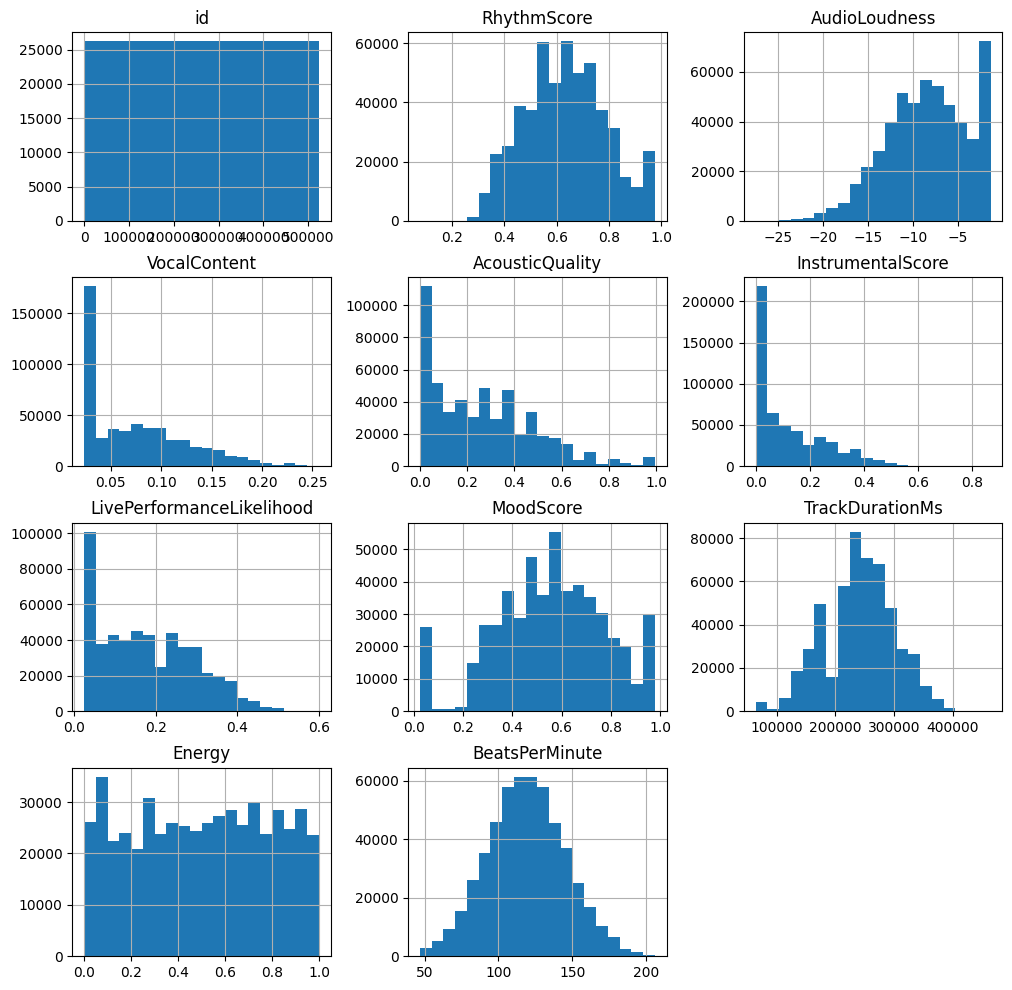

In [10]:
# Histograma de todas las variables numéricas
data.hist(figsize=(12, 12), bins=20)
plt.show()

>Tras la verificación visual de los valores de cada variable vemos que puede haber presencia de valores que estén fuera de la distribución, por lo que se procede a graficar los datos outliners en cada variable.  Para esto se separan las variables de acuerdo a su rango para ver los gráficos de una mejor manera.


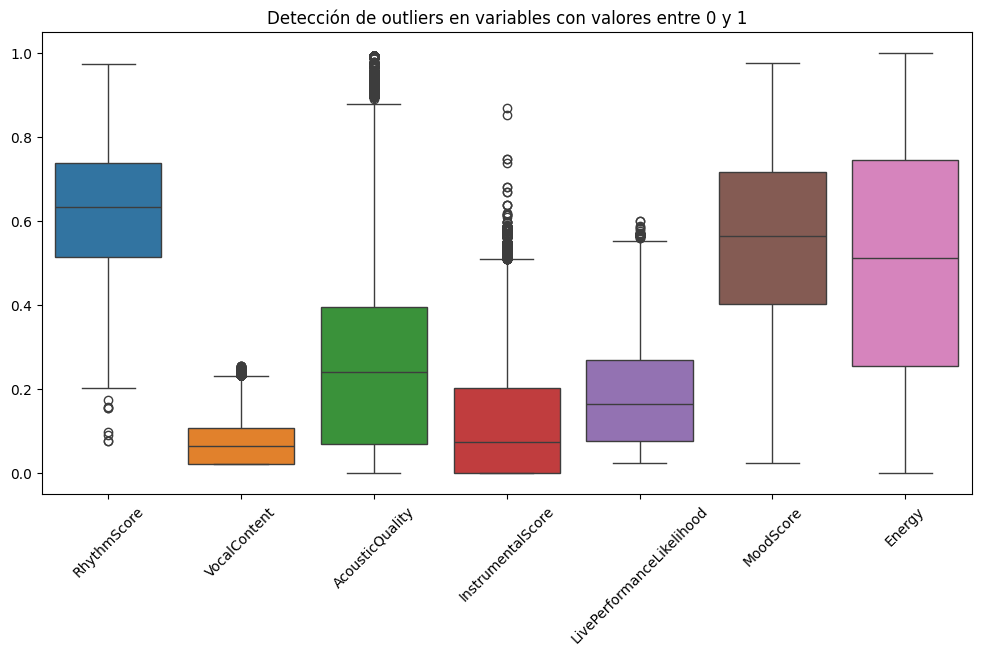

In [11]:
# Gráfica de outliners de las variables que tienen valores entre 0 y 1.
cols_df = ["RhythmScore", "VocalContent", "AcousticQuality", "InstrumentalScore", "LivePerformanceLikelihood", "MoodScore", "Energy"]
plt.figure(figsize=(12, 6))
sns.boxplot(data=data[cols_df])
plt.xticks(rotation=45)
plt.title("Detección de outliers en variables con valores entre 0 y 1")
plt.show()

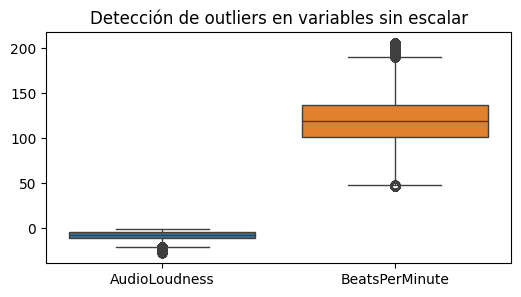

In [12]:
# Gráfica de valores para las variables con valores grandes
cols_df_2 = ["AudioLoudness", "BeatsPerMinute"]
plt.figure(figsize=(6, 3))
sns.boxplot(data=data[cols_df_2])
plt.title("Detección de outliers en variables sin escalar")
plt.show()

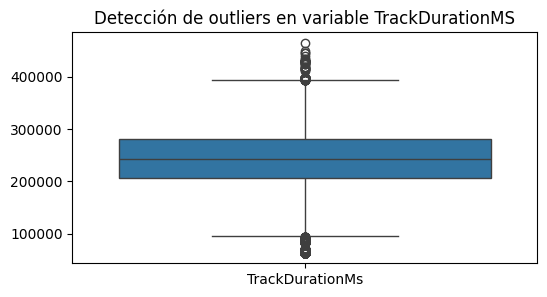

In [13]:
# Gráfico de la variable con los valores más altos
cols_3 = ["TrackDurationMs"]
plt.figure(figsize=(6, 3))
sns.boxplot(data=data[cols_3])
plt.title("Detección de outliers en variable TrackDurationMS")
plt.show()

>Las gráficas nos muestran la presencia de outliners en las variables y para verificar qué tanto pueden afectar se procede a sumar la cantidad y qué tan representativo es el total de outliners en cada variable.

In [14]:
# Verificación de outliners usando la medida de IQR para ver la cantidad de datos fuera de la tendencia
# Cálculo del IQR
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

# Límiter dl índice intercuartílico.
inf = Q1 - 1.5*IQR
sup = Q3 + 1.5*IQR
cantidad_outliers = pd.DataFrame({
    "Total": (
        (data < (inf)) | (data > (sup))
    ).sum(),
    "Porcentaje (%)": (
        ((data < (inf)) | (data > (sup))).mean() * 100
    ).round(2),
})

# Muestra todas las variables ordenadas de mayor a menor cantidad de outliers
print(cantidad_outliers.sort_values(by="Total", ascending=False))

                           Total  Porcentaje (%)
AcousticQuality             6746            1.29
TrackDurationMs             4267            0.81
InstrumentalScore           2845            0.54
BeatsPerMinute              2141            0.41
AudioLoudness               1770            0.34
VocalContent                1245            0.24
LivePerformanceLikelihood    129            0.02
RhythmScore                    8            0.00
id                             0            0.00
MoodScore                      0            0.00
Energy                         0            0.00


>Las variables presentan outliners pero, por la cantidad que hay no se considera que vayan a fectar el rendimiento del modelo, además, como la integridad de os datos fue buen, se considera que estos valores fuera de rango responden a meidas reales.  

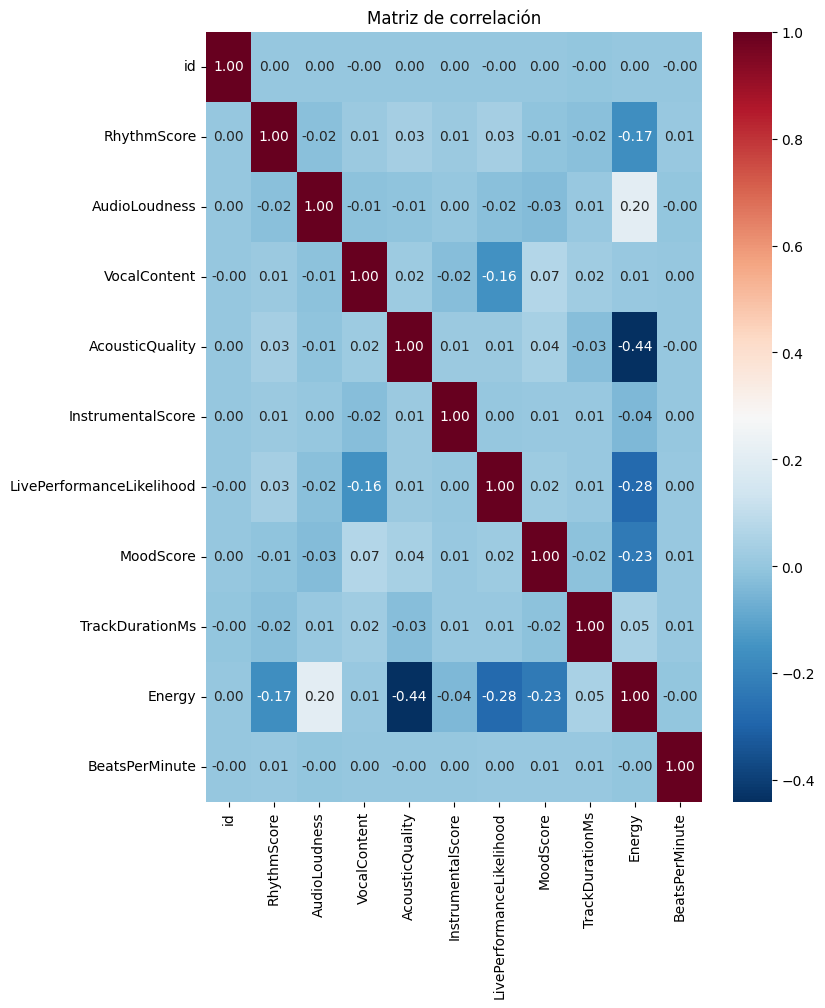

In [15]:
# Visualización de la correlación entre variables
plt.figure(figsize=(8, 10))
sns.heatmap(data.corr(method="spearman"), annot=True, fmt='.2f', cmap='RdBu_r')
plt.title('Matriz de correlación')
plt.show()

In [16]:
# Análisis de parejas de variables más correladas entre sí.  Se Imprimen las primeras columnas buscando las variables que
# más correlación tienen.
correlation_matrix = data.corr()
corr_pairs = correlation_matrix.abs().unstack().sort_values(kind="quicksort", ascending=False).reset_index()
corr_pairs.columns = ['Variable 1', 'Variable 2', 'Correlación']
#orr_pairs = corr_pairs[corr_pairs['Variable 1'] != corr_pairs['Variable 2']]
print(corr_pairs.head(15))

                   Variable 1                 Variable 2  Correlación
0                          id                         id     1.000000
1               AudioLoudness              AudioLoudness     1.000000
2                 RhythmScore                RhythmScore     1.000000
3             AcousticQuality            AcousticQuality     1.000000
4                VocalContent               VocalContent     1.000000
5             TrackDurationMs            TrackDurationMs     1.000000
6                   MoodScore                  MoodScore     1.000000
7   LivePerformanceLikelihood  LivePerformanceLikelihood     1.000000
8           InstrumentalScore          InstrumentalScore     1.000000
9              BeatsPerMinute             BeatsPerMinute     1.000000
10                     Energy                     Energy     1.000000
11            AcousticQuality                     Energy     0.418184
12                     Energy            AcousticQuality     0.418184
13  LivePerformanceL

>El análisis de la correlación entre las variables nos muestra que las variables de entrada tienen muy poca correlación conla variable de salida y que la variable "Energy" tiene una correlación lineal, entre moderada y baja, con las demás variables.

Terminada la etapa de análisis y verificación del conjunto de datos y las variables, se va a separar el conjunto de datos con una proporción de 75% para train y 25% para test, ya que, hay muestras suficientes (más de quinentas mil) para que esta distribución se a decuada.

Luego de separar los datos se va a realizar una estandarización de todas las variables, excepto la variable "id" porque esta variable no aporta información para la predicción de los beats por minuto de las canciones.

In [17]:
# Separación del conjuto de datos y estandarización de las variables

X = data.drop(columns=["id", "BeatsPerMinute"])
y = data["BeatsPerMinute"]

# Separación de los datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# Estandarización de las variables

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_train_scaled = scaler.fit_transform(X_train_scaled)
X_test_scaled = X_test.copy()
X_test_scaled = scaler.transform(X_test_scaled)

# Selección y entrenamiento de modelos — Esteban Calle

## Objetivo

Comparar modelos para predecir `BeatsPerMinute` a partir de las nueve
características musicales disponibles.

Es un problema de aprendizaje supervisado de regresión porque la variable
objetivo es numérica.

## Datos y metodología

Se mantiene la división propuesta en el análisis inicial:

- 75 % para entrenamiento: 393.123 observaciones.
- 25 % para prueba final: 131.041 observaciones.
- Se excluye `id` de las variables predictoras.
- Se utiliza `random_state=42` para reproducir la división.

Los modelos se comparan mediante validación cruzada de cinco particiones
dentro del 75 % de entrenamiento. El 25 % de prueba permanece reservado
para la evaluación final.

En la regresión lineal, el escalado se incluye en un pipeline y se ajusta
solo con los datos de entrenamiento de cada partición.

## Modelos evaluados

1. **Referencia básica:** predice siempre la media de BPM del entrenamiento.
2. **Regresión lineal múltiple:** combina linealmente las nueve características.
3. **Árbol de regresión:** permite representar relaciones no lineales.
   Se comparan profundidades máximas de 3, 6 y 10, manteniendo un mínimo
   de 50 observaciones por hoja.

## Métricas

- **RMSE:** raíz del error cuadrático medio. Penaliza especialmente los
  errores grandes y se expresa en BPM. Cuanto menor, mejor.
- **MAE:** promedio del error absoluto, expresado en BPM. Cuanto menor, mejor.
- **R²:** mide el rendimiento respecto a una referencia constante basada
  en la media del conjunto evaluado. Puede ser negativo; cuanto mayor, mejor.

In [18]:
print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Entrenamiento escalado:", X_train_scaled.shape)
print("Prueba escalada:", X_test_scaled.shape)

Entrenamiento: (393123, 9)
Prueba: (131041, 9)
Entrenamiento escalado: (393123, 9)
Prueba escalada: (131041, 9)


In [19]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

# Referencia: predice siempre la media de BPM del entrenamiento
modelo_base = DummyRegressor(strategy="mean")
modelo_base.fit(X_train_scaled, y_train)

# Regresión lineal: aprende a combinar las nueve características
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train_scaled, y_train)

print("Los dos modelos están entrenados.")
print(
    "BPM que predice siempre el modelo base:",
    round(float(y_train.mean()), 2)
)

Los dos modelos están entrenados.
BPM que predice siempre el modelo base: 119.06


In [20]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Las mismas cinco particiones para ambos modelos
cv = KFold(n_splits=5, shuffle=True, random_state=42)

modelos = {
    "Base (media)": DummyRegressor(strategy="mean"),
    "Regresión lineal": make_pipeline(
        StandardScaler(),
        LinearRegression()
    )
}

resultados = []

for nombre, modelo in modelos.items():
    scores = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "RMSE": "neg_root_mean_squared_error",
            "MAE": "neg_mean_absolute_error",
            "R2": "r2"
        }
    )

    resultados.append({
        "Modelo": nombre,
        "RMSE CV": -scores["test_RMSE"].mean(),
        "MAE CV": -scores["test_MAE"].mean(),
        "R² CV": scores["test_R2"].mean()
    })

tabla_resultados = pd.DataFrame(resultados)
display(tabla_resultados.round(4))

,Modelo,RMSE CV,MAE CV,R² CV
0,Base (media),26.4722,21.2024,-0.0000
1,Regresión lineal,26.4705,21.2008,0.0001


## Resultados: referencia básica y regresión lineal

| Modelo | RMSE medio CV | MAE medio CV | R² medio CV |
|---|---:|---:|---:|
| Referencia: media | 26,4722 | 21,2024 | ≈ 0 |
| Regresión lineal | 26,4705 | 21,2008 | 0,0001 |

La regresión lineal reduce el RMSE aproximadamente 0,0017 BPM respecto
a la referencia. La mejora observada es mínima.

El R² cercano a cero indica una capacidad explicativa muy limitada en
las particiones de validación. Este resultado es coherente con las
correlaciones individuales débiles observadas en el análisis exploratorio,
pero no descarta relaciones no lineales o interacciones entre variables.

Estos resultados proceden de validación cruzada, no del conjunto de
prueba final.

In [21]:
from sklearn.tree import DecisionTreeRegressor

resultados_arbol = []

for profundidad in [3, 6, 10]:
    modelo = DecisionTreeRegressor(
        max_depth=profundidad,
        min_samples_leaf=50,
        random_state=42
    )

    scores = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        return_train_score=True
    )

    resultados_arbol.append({
        "Profundidad": profundidad,
        "RMSE entrenamiento": -scores["train_score"].mean(),
        "RMSE validación": -scores["test_score"].mean()
    })

display(pd.DataFrame(resultados_arbol).round(4))

,Profundidad,RMSE entrenamiento,RMSE validación
0,3,26.4627,26.4678
1,6,26.4450,26.4751
2,10,26.3805,26.5342


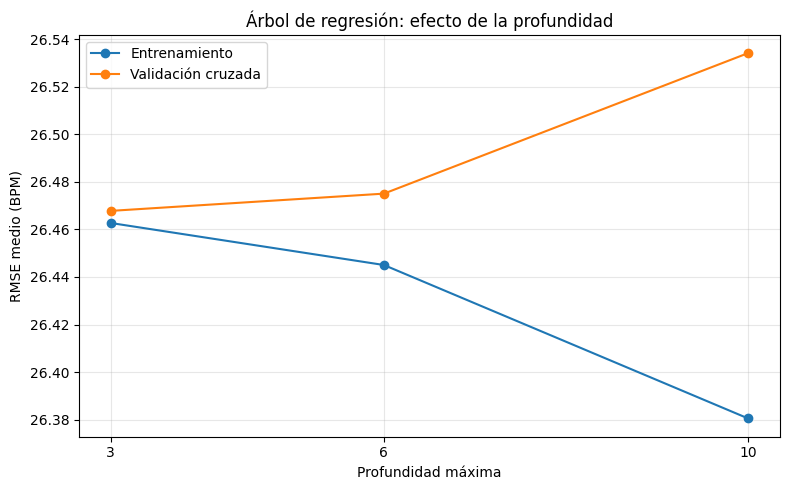

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    tabla_arbol["Profundidad"],
    tabla_arbol["RMSE entrenamiento"],
    marker="o",
    label="Entrenamiento"
)

ax.plot(
    tabla_arbol["Profundidad"],
    tabla_arbol["RMSE validación"],
    marker="o",
    label="Validación cruzada"
)

ax.set(
    title="Árbol de regresión: efecto de la profundidad",
    xlabel="Profundidad máxima",
    ylabel="RMSE medio (BPM)"
)
ax.set_xticks(tabla_arbol["Profundidad"])
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

## Interpretación del árbol de regresión

Se compararon profundidades máximas de 3, 6 y 10 mediante validación
cruzada de cinco particiones dentro del 75 % de entrenamiento.

- La profundidad 3 obtuvo el menor RMSE medio de validación: 26,4678 BPM.
- Al aumentar la profundidad, disminuyó el error de entrenamiento,
  pero aumentó el de validación. Esto muestra una tendencia al sobreajuste.
- La mejora frente al modelo base fue marginal: aproximadamente
  0,0044 BPM de RMSE. No demuestra por sí sola una ventaja estable.

El eje vertical está ampliado para visualizar diferencias pequeñas:
la separación entre las curvas no representa un cambio de varios BPM.

El 25 % de prueba final permanece reservado y no se ha utilizado
para seleccionar la profundidad.

## Random Forest: combinación de árboles

Se evalúa Random Forest para comprobar si combinar varios árboles
mejora la generalización frente a un árbol individual.

En esta primera prueba se utilizan 100 árboles, profundidad máxima
de 6 y un mínimo de 50 observaciones por hoja para limitar la complejidad.

Se mantienen las mismas cinco particiones de validación cruzada y
las nueve variables predictoras sin escalar. El 25 % de prueba final
permanece reservado.

In [26]:
from sklearn.ensemble import RandomForestRegressor

modelo_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=6,
    min_samples_leaf=50,
    random_state=42,
    n_jobs=-1
)

scores_rf = cross_validate(
    modelo_rf,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "RMSE": "neg_root_mean_squared_error",
        "MAE": "neg_mean_absolute_error",
        "R2": "r2"
    },
    return_train_score=True,
    n_jobs=1
)

resultado_rf = pd.DataFrame([{
    "Modelo": "Random Forest",
    "RMSE entrenamiento": -scores_rf["train_RMSE"].mean(),
    "RMSE validación": -scores_rf["test_RMSE"].mean(),
    "Desviación RMSE entre particiones": scores_rf["test_RMSE"].std(),
    "MAE validación": -scores_rf["test_MAE"].mean(),
    "R² validación": scores_rf["test_R2"].mean()
}])

display(resultado_rf.round(4))

,Modelo,RMSE entrenamiento,RMSE validación,Desviación RMSE entre particiones,MAE validación,R² validación
0,Random Forest,26.4318,26.4622,0.0379,21.1931,0.0007


## Interpretación de Random Forest

Random Forest obtuvo un RMSE medio de validación cruzada de 26,4622 BPM,
frente a 26,4722 BPM del modelo base y 26,4678 BPM del árbol de profundidad 3.

Aunque presenta el menor RMSE medio de los modelos evaluados, la mejora
frente a la referencia es de solo 0,0100 BPM.

El MAE de 21,1931 BPM indica que las predicciones se desvían, en promedio
absoluto, aproximadamente 21,19 BPM de los valores reales en validación.

El R² medio de 0,0007 muestra una capacidad explicativa muy limitada.
La desviación del RMSE entre particiones fue de 0,0379 BPM; para determinar
si la ventaja es consistente habría que comparar las diferencias entre
modelos en cada partición.

El error de entrenamiento es ligeramente menor que el de validación.
Esta diferencia, por sí sola, no demuestra un sobreajuste importante.

El 25 % de prueba final permanece reservado.

In [27]:
# Resultados del modelo base y de la regresión lineal
tabla_comparativa = tabla_resultados[["Modelo", "RMSE CV"]].copy()

# Resultados de las tres profundidades del árbol
tabla_arboles = pd.DataFrame([
    {
        "Modelo": f"Árbol (profundidad {fila['Profundidad']})",
        "RMSE CV": fila["RMSE validación"]
    }
    for fila in resultados_arbol
])

# Resultado de Random Forest
tabla_rf = pd.DataFrame([{
    "Modelo": "Random Forest",
    "RMSE CV": resultado_rf.loc[0, "RMSE validación"]
}])

# Unir y ordenar: menor error primero
tabla_comparativa = pd.concat(
    [tabla_comparativa, tabla_arboles, tabla_rf],
    ignore_index=True
).sort_values("RMSE CV").reset_index(drop=True)

# Comparar cada modelo con la referencia básica
rmse_base = tabla_resultados.loc[
    tabla_resultados["Modelo"] == "Base (media)", "RMSE CV"
].iloc[0]

tabla_comparativa["Mejora frente a base (BPM)"] = (
    rmse_base - tabla_comparativa["RMSE CV"]
)

display(tabla_comparativa.round(4))

,Modelo,RMSE CV,Mejora frente a base (BPM)
0,Random Forest,26.4622,0.0100
1,Árbol (profundidad 3),26.4678,0.0043
2,Regresión lineal,26.4705,0.0017
3,Base (media),26.4722,0.0000
4,Árbol (profundidad 6),26.4751,-0.0029
5,Árbol (profundidad 10),26.5342,-0.0621


## Comparación de los modelos

Todos los resultados corresponden a las mismas cinco particiones de
validación cruzada dentro del 75 % de entrenamiento.

Random Forest obtuvo el menor RMSE medio: 26,4622 BPM. Su mejora frente
al modelo base fue de aproximadamente 0,0100 BPM, por lo que la ventaja
observada es marginal.

El árbol de profundidad 3 y la regresión lineal también mejoraron
ligeramente la referencia. Los árboles de profundidades 6 y 10 obtuvieron
peores resultados, mostrando que aumentar la complejidad no garantizó
una mejor generalización.

La columna «Mejora frente a base» representa la reducción del RMSE:
un valor positivo indica mejora y uno negativo indica empeoramiento.
No representa una mejora en cada canción individual.

El 25 % de prueba final permanece reservado. La clasificación por RMSE
medio no demuestra por sí sola que las diferencias sean estables.

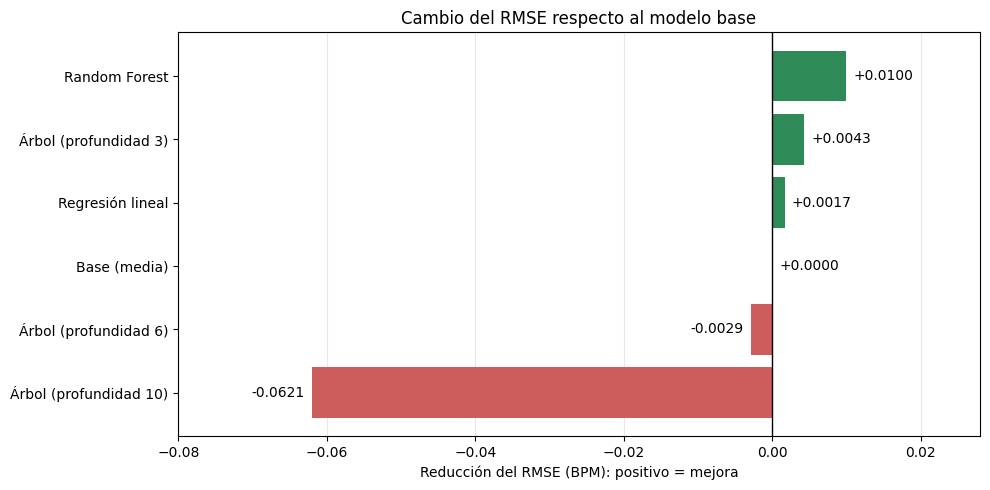

In [28]:
import matplotlib.pyplot as plt

# Mostrar cuánto mejora o empeora cada modelo frente a la media
tabla_grafica = tabla_comparativa.sort_values(
    "Mejora frente a base (BPM)",
    ascending=False
)

mejoras = tabla_grafica["Mejora frente a base (BPM)"]
colores = [
    "seagreen" if valor > 0 else
    "indianred" if valor < 0 else
    "gray"
    for valor in mejoras
]

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    tabla_grafica["Modelo"],
    mejoras,
    color=colores
)

# Etiquetar cada barra con su valor
for posicion, valor in enumerate(mejoras):
    ax.annotate(
        f"{valor:+.4f}",
        xy=(valor, posicion),
        xytext=(5 if valor >= 0 else -5, 0),
        textcoords="offset points",
        va="center",
        ha="left" if valor >= 0 else "right"
    )

ax.axvline(0, color="black", linewidth=1)
ax.invert_yaxis()
ax.set(
    title="Cambio del RMSE respecto al modelo base",
    xlabel="Reducción del RMSE (BPM): positivo = mejora"
)
ax.margins(x=0.25)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Lectura de la gráfica

Las barras verdes indican una reducción del RMSE frente a predecir
siempre la media. Las rojas indican un aumento del error.

Random Forest presenta la mayor reducción, de aproximadamente
0,0100 BPM. Las diferencias son pequeñas: el RMSE completo de todos
los modelos se encuentra entre aproximadamente 26,46 y 26,53 BPM.

La gráfica muestra diferencias entre promedios de validación cruzada;
no incluye intervalos de incertidumbre ni demuestra significación estadística.

## Entrenamiento del candidato para evaluación final

Se selecciona provisionalmente Random Forest por obtener el menor RMSE
medio de validación cruzada entre los modelos probados.

La mejora frente al modelo base es marginal; esta selección no implica
que se haya demostrado una ventaja estable o una utilidad práctica.

Se entrena con todo el 75 % de entrenamiento, manteniendo los parámetros
evaluados. El 25 % de prueba permanece reservado para la evaluación final.

In [29]:
from sklearn.base import clone

# Crear una copia con los mismos parámetros y entrenarla
modelo_final = clone(modelo_rf)
modelo_final.fit(X_train, y_train)

print("Random Forest entrenado con", len(X_train), "observaciones.")
print("El conjunto de prueba sigue sin utilizarse.")

Random Forest entrenado con 393123 observaciones.
El conjunto de prueba sigue sin utilizarse.
